# Advanced Algorithms and Computational Complexity: An Empirical and Theoretical Study
**Course:** SC612 - Discrete Mathematics  
**Academic Level:** Master of Science in Information Technology (MSc IT)  
**Primary Reference:** Kenneth H. Rosen, *Discrete Mathematics and Its Applications*, 8th Edition, Chapter 3  
**Author / Student:** Hamza Payawala (ID: 202612089)  
**Institution:** Dhirubhai Ambani University  
**Instructor:** Prof. Gopinath Panda  
**Date:** 17/11/2026  

---

## Executive Overview and Notebook Scope
This interactive laboratory notebook demonstrates the core principles of algorithmic theory, algorithmic taxonomy, asymptotic growth of functions, and computational complexity as presented in Chapter 3 of Kenneth H. Rosen's *Discrete Mathematics and Its Applications* (8th Edition). 

The notebook is organized into four rigorous sections:
1. **Foundational Algorithmics:** The formal definition of an algorithm, the seven required properties, and invariant verification.
2. **Search and Sort Paradigms:** Implementation, instrumentation, and step-by-step operation counting for Linear Search, Binary Search, Bubble Sort (with early-exit optimization), Insertion Sort, and the Greedy Cashier's algorithm.
3. **Growth of Functions:** Mathematical and graphical analysis of Big-$, Big-$\Omega$, and Big-$\Theta$, illustrating the asymptotic hierarchy under fixed constants  > 2$ and  > 1$.
4. **Empirical Complexity Analysis:** Direct measurement of operation counts across Best, Average, and Worst cases, confirming theoretical $\Theta$-bounds with Matplotlib visualizations.


### 0. Environment Setup and Visualization Configuration
The following cell imports standard mathematical and visualization libraries (`matplotlib`, `numpy`, `time`, and `math`). Standard styling ensures clear visual contrast for academic reporting.


In [1]:
import math
import time
import random
import numpy as np
import matplotlib.pyplot as plt

# Configure clean, publication-ready plot aesthetics
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True
print("Environment successfully initialized with NumPy and Matplotlib.")


Environment successfully initialized with NumPy and Matplotlib.


## 1. Foundations of Algorithms (Rosen Section 3.1)
According to Rosen (Section 3.1), an algorithm is a *finite sequence of precise instructions for solving a problem or performing a computation*. Every valid algorithm must exhibit seven essential properties:
1. **Input:** Specified domain.
2. **Output:** Specified solution range.
3. **Definiteness:** Explicit, unambiguous instructions.
4. **Correctness:** Correct output for all valid inputs.
5. **Finiteness:** Guaranteed halting in a finite sequence of operations.
6. **Effectiveness:** Feasible, elementary steps.
7. **Generality:** Applicable to an entire class of problem instances.

### Algorithm 1: Finding the Maximum Element
The procedure iterates through an array $a_1, a_2, \dots, a_n$, maintaining a running maximum `max_val` governed by the loop invariant:
$$\text{At loop termination at index } i, \quad \text{max\_val} = \max(a_1, \dots, a_i).$$


In [2]:
def find_max_instrumented(arr: list[int | float]) -> tuple[int | float, int]:
    """
    Rosen Section 3.1, Algorithm 1: Finding the maximum element.
    Instrumented to count exact key comparisons.
    """
    if not arr:
        raise ValueError("Input array must be non-empty.")
    
    comparisons = 0
    max_val = arr[0]
    
    for i in range(1, len(arr)):
        comparisons += 1
        if arr[i] > max_val:
            max_val = arr[i]
            
    return max_val, comparisons

# Verification across varied inputs
test_cases = [
    [18, 42, 7, 99, 54, 23, 88],
    [5, 4, 3, 2, 1],
    [-100, -20, -50, -5, -80],
    [42]
]

print("=== Algorithm 1: Max-Finding Verification ===")
for test in test_cases:
    maximum, comps = find_max_instrumented(test)
    test_str = str(test)
    print(f"Input: {test_str:<30} -> Max: {maximum:<4} | Comparisons: {comps} (Theoretical: n-1 = {len(test)-1})")


=== Algorithm 1: Max-Finding Verification ===
Input: [18, 42, 7, 99, 54, 23, 88]    -> Max: 99   | Comparisons: 6 (Theoretical: n-1 = 6)
Input: [5, 4, 3, 2, 1]                -> Max: 5    | Comparisons: 4 (Theoretical: n-1 = 4)
Input: [-100, -20, -50, -5, -80]      -> Max: -5   | Comparisons: 4 (Theoretical: n-1 = 4)
Input: [42]                           -> Max: 42   | Comparisons: 0 (Theoretical: n-1 = 0)


**Observation on Algorithm 1:**  
Regardless of whether the input sequence is sorted, reverse-sorted, or randomized, the loop executes exactly $n - 1$ comparisons for an input of size $n$. The time complexity is invariant at $\Theta(n)$, and auxiliary space is $\Theta(1)$ (in-place).


## 2. Searching Paradigms: Linear Search vs Binary Search (Rosen Section 3.1)
Searching locates a target $x$ within a sequence $a_1, a_2, \dots, a_n$, returning its index or reporting absence.

- **Linear Search:** Evaluates elements sequentially. Requires no sorted ordering.
- **Binary Search:** Requires a monotonically sorted sequence ($a_1 \le a_2 \le \dots \le a_n$). Employs divide-and-conquer to bisect the search space in each pass, achieving logarithmic performance.


In [3]:
def linear_search_instrumented(arr: list, target) -> tuple[int, int]:
    """
    Rosen Section 3.1, Algorithm 2: Linear Search.
    Returns (index, comparisons). Index is 0-based, or -1 if not found.
    """
    comparisons = 0
    for i in range(len(arr)):
        comparisons += 1
        if arr[i] == target:
            return i, comparisons
    return -1, comparisons


def binary_search_instrumented(arr: list, target) -> tuple[int, int]:
    """
    Rosen Section 3.1, Algorithm 3: Binary Search on sorted array.
    Returns (index, comparisons).
    """
    comparisons = 0
    low = 0
    high = len(arr) - 1
    
    while low <= high:
        comparisons += 1
        mid = (low + high) // 2
        if arr[mid] == target:
            return mid, comparisons
        elif arr[mid] < target:
            low = mid + 1
        else:
            high = mid - 1
            
    return -1, comparisons

# Practical demonstration
data = [12, 24, 37, 45, 59, 68, 73, 81, 92, 105, 118, 130, 145, 160, 178, 199]
target_present = 81
target_absent = 100

print(f"Data set ({len(data)} items): {data}")
idx_lin, cmp_lin = linear_search_instrumented(data, target_present)
idx_bin, cmp_bin = binary_search_instrumented(data, target_present)
print(f"Search for {target_present} (Present):")
print(f"  Linear Search -> Index: {idx_lin}, Comparisons: {cmp_lin}")
print(f"  Binary Search -> Index: {idx_bin}, Comparisons: {cmp_bin}")

idx_lin_abs, cmp_lin_abs = linear_search_instrumented(data, target_absent)
idx_bin_abs, cmp_bin_abs = binary_search_instrumented(data, target_absent)
print(f"Search for {target_absent} (Absent):")
print(f"  Linear Search -> Index: {idx_lin_abs}, Comparisons: {cmp_lin_abs} (n = {len(data)})")
print(f"  Binary Search -> Index: {idx_bin_abs}, Comparisons: {cmp_bin_abs} (<= floor(log2(n))+1 = {math.floor(math.log2(len(data)))+1})")


Data set (16 items): [12, 24, 37, 45, 59, 68, 73, 81, 92, 105, 118, 130, 145, 160, 178, 199]
Search for 81 (Present):
  Linear Search -> Index: 7, Comparisons: 8
  Binary Search -> Index: 7, Comparisons: 1
Search for 100 (Absent):
  Linear Search -> Index: -1, Comparisons: 16 (n = 16)
  Binary Search -> Index: -1, Comparisons: 4 (<= floor(log2(n))+1 = 5)


### Empirical Scaling of Search Algorithms
The cell below measures comparison counts across input sizes from $n = 10$ to $n = 10,000$ for worst-case scenarios (searching for an absent element), contrasting $O(n)$ with $O(\log n)$.


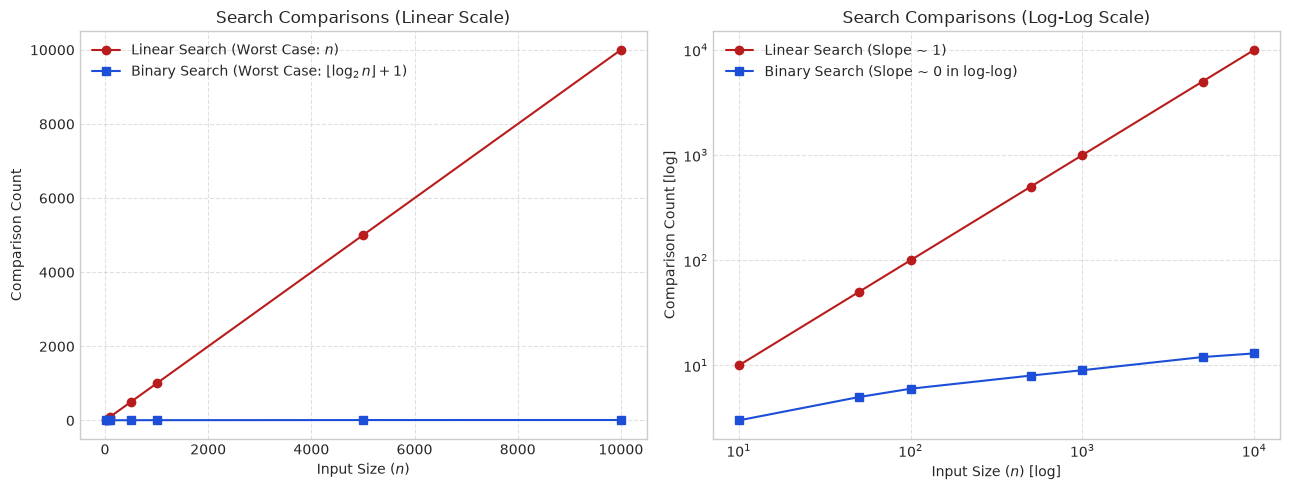

In [4]:
sizes = [10, 50, 100, 500, 1000, 5000, 10000]
lin_comps = []
bin_comps = []

for n in sizes:
    arr = list(range(n))
    target = -1  # Guaranteed absent: worst-case trigger
    
    _, c_lin = linear_search_instrumented(arr, target)
    _, c_bin = binary_search_instrumented(arr, target)
    
    lin_comps.append(c_lin)
    bin_comps.append(c_bin)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Linear scale
ax1.plot(sizes, lin_comps, 'o-', color='#B91C1C', label=r'Linear Search (Worst Case: $n$)')
ax1.plot(sizes, bin_comps, 's-', color='#1D4ED8', label=r'Binary Search (Worst Case: $\lfloor\log_2 n\rfloor + 1$)')
ax1.set_title("Search Comparisons (Linear Scale)")
ax1.set_xlabel("Input Size ($n$)")
ax1.set_ylabel("Comparison Count")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Log-Log scale
ax2.plot(sizes, lin_comps, 'o-', color='#B91C1C', label='Linear Search (Slope ~ 1)')
ax2.plot(sizes, bin_comps, 's-', color='#1D4ED8', label='Binary Search (Slope ~ 0 in log-log)')
ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_title("Search Comparisons (Log-Log Scale)")
ax2.set_xlabel("Input Size ($n$) [log]")
ax2.set_ylabel("Comparison Count [log]")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.show()


**Analytical Observations on Search Algorithms:**  
1. **Linear Search:** Comparisons scale with strict proportionality to $n$. At $n = 10,000$, Linear Search requires exactly $10,000$ operations in the worst case ($\Theta(n)$).
2. **Binary Search:** Scales logarithmically. At $n = 10,000$, it terminates in merely $14$ comparisons ($\lfloor \log_2(10000) \rfloor + 1 = 14$), illustrating the power of divide-and-conquer.


## 3. Sorting Paradigms: Bubble Sort and Insertion Sort (Rosen Section 3.1)
Sorting organizes an arbitrary sequence into non-decreasing order.

- **Optimized Bubble Sort:** Compares adjacent pairs. When augmented with a swap-detection flag, it halts immediately if a pass generates zero swaps.  
  *Crucial Bound:* Best-case complexity is $\Theta(n)$ with exactly $n - 1$ comparisons and $0$ swaps.
- **Insertion Sort:** Iteratively shifts larger elements to the right to place each key into its sorted relative position. Best-case is also $\Theta(n)$ with $n - 1$ comparisons.
- **Merge Sort (Benchmark):** Canonical divide-and-conquer comparison sort operating in $\Theta(n \log n)$ worst-case.


In [5]:
def bubble_sort_instrumented(arr: list) -> tuple[list, int, int]:
    """
    Rosen Section 3.1, Algorithm 4: Bubble Sort with early-exit optimization.
    Returns (sorted_arr, comparisons, swaps).
    """
    a = arr.copy()
    n = len(a)
    comps = 0
    swaps = 0
    
    for i in range(n - 1):
        swapped = False
        for j in range(n - 1 - i):
            comps += 1
            if a[j] > a[j + 1]:
                a[j], a[j + 1] = a[j + 1], a[j]
                swaps += 1
                swapped = True
        # If no swaps occurred in this pass, the array is already sorted
        if not swapped:
            break
            
    return a, comps, swaps


def insertion_sort_instrumented(arr: list) -> tuple[list, int, int]:
    """
    Rosen Section 3.1, Algorithm 5: Insertion Sort.
    Returns (sorted_arr, comparisons, shifts).
    """
    a = arr.copy()
    n = len(a)
    comps = 0
    shifts = 0
    
    for j in range(1, n):
        key = a[j]
        i = j - 1
        while i >= 0:
            comps += 1
            if a[i] > key:
                a[i + 1] = a[i]
                shifts += 1
                i -= 1
            else:
                break
        a[i + 1] = key
        
    return a, comps, shifts

# Verification of Best-Case vs Worst-Case
n_test = 8
sorted_arr = list(range(1, n_test + 1))
reversed_arr = list(range(n_test, 0, -1))

print(f"--- Optimized Bubble Sort Verification (n = {n_test}) ---")
_, b_c_best, b_s_best = bubble_sort_instrumented(sorted_arr)
_, b_c_worst, b_s_worst = bubble_sort_instrumented(reversed_arr)
print(f"BEST CASE (Sorted):   Comparisons = {b_c_best} (n-1 = {n_test-1}), Swaps = {b_s_best} -> Theta(n)")
print(f"WORST CASE (Reversed): Comparisons = {b_c_worst} (n(n-1)/2 = {n_test*(n_test-1)//2}), Swaps = {b_s_worst} -> Theta(n^2)")

print(f"\n--- Insertion Sort Verification (n = {n_test}) ---")
_, i_c_best, i_s_best = insertion_sort_instrumented(sorted_arr)
_, i_c_worst, i_s_worst = insertion_sort_instrumented(reversed_arr)
print(f"BEST CASE (Sorted):   Comparisons = {i_c_best} (n-1 = {n_test-1}), Shifts = {i_s_best} -> Theta(n)")
print(f"WORST CASE (Reversed): Comparisons = {i_c_worst} (n(n-1)/2 = {n_test*(n_test-1)//2}), Shifts = {i_s_worst} -> Theta(n^2)")


--- Optimized Bubble Sort Verification (n = 8) ---
BEST CASE (Sorted):   Comparisons = 7 (n-1 = 7), Swaps = 0 -> Theta(n)
WORST CASE (Reversed): Comparisons = 28 (n(n-1)/2 = 28), Swaps = 28 -> Theta(n^2)

--- Insertion Sort Verification (n = 8) ---
BEST CASE (Sorted):   Comparisons = 7 (n-1 = 7), Shifts = 0 -> Theta(n)
WORST CASE (Reversed): Comparisons = 28 (n(n-1)/2 = 28), Shifts = 28 -> Theta(n^2)


**Analytical Observation on Optimized Bubble Sort and Insertion Sort:**  
1. **Best-Case Alignment:** When the input sequence is pre-sorted, the early-exit check in Bubble Sort verifies sortedness in one pass of $n - 1$ comparisons with 0 swaps, confirming the theoretical $\Theta(n)$ best-case bound. Similarly, Insertion Sort conducts exactly one comparison per outer loop iteration ($n - 1$ comparisons, 0 shifts), yielding $\Theta(n)$.
2. **Worst-Case Cost:** For reverse-ordered inputs, both algorithms execute $\sum_{k=1}^{n-1} k = \frac{n(n-1)}{2}$ comparisons and $O(n^2)$ data movements.


## 4. The Greedy Algorithmic Paradigm: Cashier's Algorithm (Rosen Section 3.1)
The greedy approach makes locally optimal choices at each stage without backtracking.

### Rosen Cashier's Problem (Algorithm 6)
- **Canonical Currency (e.g., US Quarters, Dimes, Nickels, Pennies: [25, 10, 5, 1]):** The greedy algorithm is provably optimal.
- **Non-Canonical Currency Counterexample (e.g., Denominations: [4, 3, 1] for amount 6):** Greedy fails to find the global minimum coin count.


In [6]:
def greedy_change(denominations: list[int], amount: int) -> dict[int, int]:
    """
    Rosen Section 3.1, Algorithm 6: Greedy Cashier's Algorithm.
    denominations: sorted descending list of coin values.
    """
    coins = {}
    remaining = amount
    for coin in sorted(denominations, reverse=True):
        count = remaining // coin
        coins[coin] = count
        remaining -= count * coin
    return coins


def optimal_change_dp(denominations: list[int], amount: int) -> dict[int, int]:
    """
    Dynamic programming reference solver for minimal coin count.
    """
    dp = [float('inf')] * (amount + 1)
    parent = [-1] * (amount + 1)
    coin_used = [-1] * (amount + 1)
    dp[0] = 0
    
    for a in range(1, amount + 1):
        for c in denominations:
            if a >= c and dp[a - c] + 1 < dp[a]:
                dp[a] = dp[a - c] + 1
                parent[a] = a - c
                coin_used[a] = c
                
    # Reconstruct optimal selection
    sol = {c: 0 for c in denominations}
    curr = amount
    while curr > 0:
        c = coin_used[curr]
        sol[c] += 1
        curr = parent[curr]
    return sol

# Experiment 1: Canonical US Denominations (amount = 67 cents)
us_coins = [25, 10, 5, 1]
amt_1 = 67
greedy_us = greedy_change(us_coins, amt_1)
optimal_us = optimal_change_dp(us_coins, amt_1)

print(f"=== Experiment 1: Canonical US System (Amount = {amt_1}¢) ===")
print(f"Greedy Allocation:  {greedy_us} (Total Coins: {sum(greedy_us.values())})")
print(f"Optimal Allocation: {optimal_us} (Total Coins: {sum(optimal_us.values())})")
print(f"Result: Greedy achieves global optimum? {sum(greedy_us.values()) == sum(optimal_us.values())}")

# Experiment 2: Non-Canonical Counterexample (Denominations: [4, 3, 1], amount = 6)
arbitrary_coins = [4, 3, 1]
amt_2 = 6
greedy_arb = greedy_change(arbitrary_coins, amt_2)
optimal_arb = optimal_change_dp(arbitrary_coins, amt_2)

print(f"\n=== Experiment 2: Non-Canonical Counterexample (Amount = {amt_2}) ===")
print(f"Greedy Allocation:  {greedy_arb} -> 4*1 + 1*2 = 3 coins: {greedy_arb}")
print(f"Optimal Allocation: {optimal_arb} -> 3*2 = 2 coins: {optimal_arb}")
print(f"Result: Greedy achieves global optimum? {sum(greedy_arb.values()) == sum(optimal_arb.values())} (GREEDY SUB-OPTIMAL!)")


=== Experiment 1: Canonical US System (Amount = 67¢) ===
Greedy Allocation:  {25: 2, 10: 1, 5: 1, 1: 2} (Total Coins: 6)
Optimal Allocation: {25: 2, 10: 1, 5: 1, 1: 2} (Total Coins: 6)
Result: Greedy achieves global optimum? True

=== Experiment 2: Non-Canonical Counterexample (Amount = 6) ===
Greedy Allocation:  {4: 1, 3: 0, 1: 2} -> 4*1 + 1*2 = 3 coins: {4: 1, 3: 0, 1: 2}
Optimal Allocation: {4: 0, 3: 2, 1: 0} -> 3*2 = 2 coins: {4: 0, 3: 2, 1: 0}
Result: Greedy achieves global optimum? False (GREEDY SUB-OPTIMAL!)


**Analytical Observation on the Greedy Paradigm:**  
In the non-canonical system $\{4, 3, 1\}$ with target $6$, the greedy algorithm selects the single largest coin ($4$), leaving a remainder of $2$, which requires two $1$-cent coins for a total of $3$ coins ($\{4, 1, 1\}$). The global optimum is two $3$-cent coins ($\{3, 3\}$, total 2 coins). This concretely proves that the greedy choice property does not guarantee global optimality without underlying matroidal or canonical structures.


## 5. Growth of Functions and Asymptotic Analysis (Rosen Section 3.2)
Asymptotic notations characterize the growth rate of functions as $n \to \infty$, abstracting away hardware differences.

### Mathematical Definitions:
1. **Big-$O$ (Upper Bound):** $f(n)$ is $O(g(n))$ if $\exists C > 0, k \ge 0$ such that $|f(n)| \le C |g(n)|, \forall n > k$.
2. **Big-$\Omega$ (Lower Bound):** $f(n)$ is $\Omega(g(n))$ if $\exists C > 0, k \ge 0$ such that $|f(n)| \ge C |g(n)|, \forall n > k$.
3. **Big-$\Theta$ (Tight Bound):** $f(n)$ is $\Theta(g(n)) \iff f(n) \in O(g(n))$ and $f(n) \in \Omega(g(n))$.

### Asymptotic Hierarchy
Under the explicit assumptions that **$b > 2$** and **$c > 1$** are fixed constants, the standard function classes satisfy the strict dominance ordering:
$$1 \prec \log n \prec n \prec n \log n \prec n^c \prec b^n \prec n! \prec n^n.$$

The cell below plots these comparative growth curves across small and medium domains.


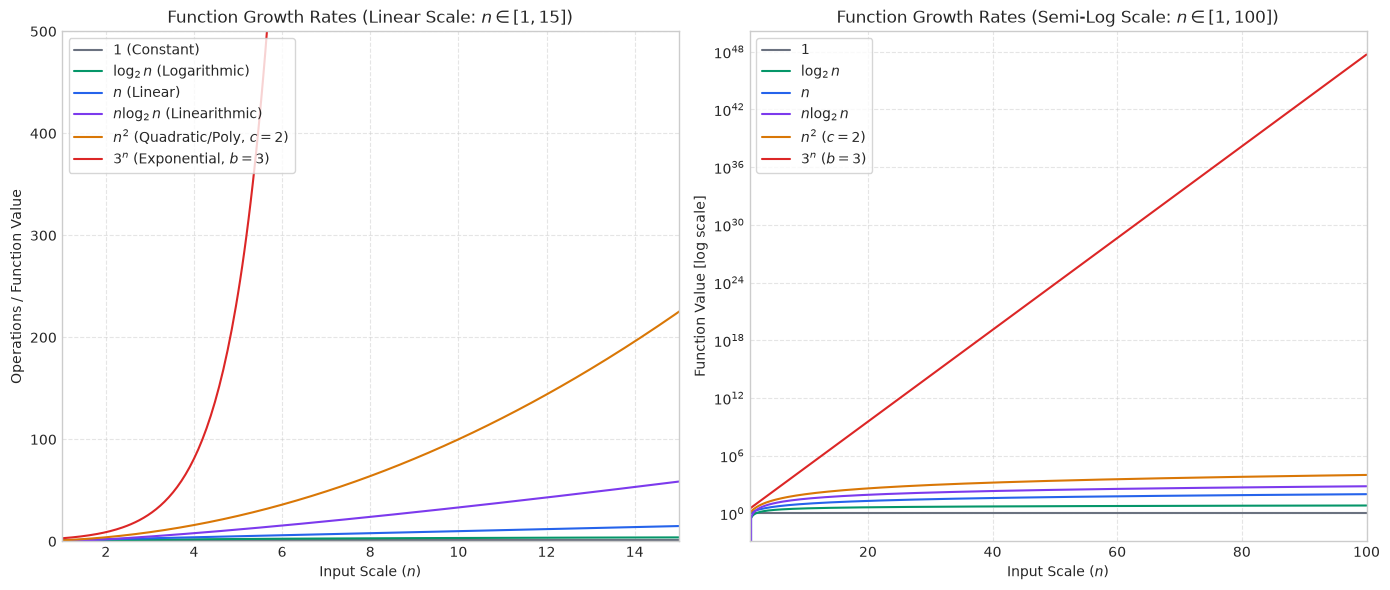

In [7]:
# Generate continuous domain values for visualization
n_small = np.linspace(1, 20, 400)
n_med = np.linspace(1, 100, 400)

# Fixed constants as specified
b_const = 3.0  # b > 2
c_const = 2.0  # c > 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Linear Scale (showing explosive divergence of exponential and factorial)
ax1.plot(n_small, [1]*len(n_small), label='$1$ (Constant)', color='#6B7280')
ax1.plot(n_small, np.log2(n_small), label='$\\log_2 n$ (Logarithmic)', color='#059669')
ax1.plot(n_small, n_small, label='$n$ (Linear)', color='#2563EB')
ax1.plot(n_small, n_small * np.log2(n_small), label='$n \\log_2 n$ (Linearithmic)', color='#7C3AED')
ax1.plot(n_small, n_small**c_const, label=f'$n^{{{int(c_const)}}}$ (Quadratic/Poly, $c={int(c_const)}$)', color='#D97706')
ax1.plot(n_small, b_const**n_small, label=f'${int(b_const)}^n$ (Exponential, $b={int(b_const)}$)', color='#DC2626')

ax1.set_ylim(0, 500)
ax1.set_xlim(1, 15)
ax1.set_title("Function Growth Rates (Linear Scale: $n \\in [1, 15]$)")
ax1.set_xlabel("Input Scale ($n$)")
ax1.set_ylabel("Operations / Function Value")
ax1.legend(loc='upper left', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Semi-Logarithmic Scale (showing global dominance across wider range)
ax2.plot(n_med, [1]*len(n_med), label='$1$', color='#6B7280')
ax2.plot(n_med, np.log2(n_med), label='$\\log_2 n$', color='#059669')
ax2.plot(n_med, n_med, label='$n$', color='#2563EB')
ax2.plot(n_med, n_med * np.log2(n_med), label='$n \\log_2 n$', color='#7C3AED')
ax2.plot(n_med, n_med**c_const, label=f'$n^{{{int(c_const)}}}$ ($c={int(c_const)}$)', color='#D97706')
ax2.plot(n_med, b_const**n_med, label=f'${int(b_const)}^n$ ($b={int(b_const)}$)', color='#DC2626')

ax2.set_yscale('log')
ax2.set_xlim(1, 100)
ax2.set_title("Function Growth Rates (Semi-Log Scale: $n \\in [1, 100]$)")
ax2.set_xlabel("Input Scale ($n$)")
ax2.set_ylabel("Function Value [log scale]")
ax2.legend(loc='upper left', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.show()


### Empirical Numerical Comparison of Growth Hierarchy
The table generated below demonstrates the explosive operational expansion between polynomial and exponential growth.


In [8]:
test_n_values = [10, 20, 30, 50]

print(f"{'Function':<16} | {'n = 10':<15} | {'n = 20':<15} | {'n = 30':<18} | {'n = 50':<20}")
print("-" * 88)

funcs = [
    ("1 (Constant)", lambda n: 1),
    ("log2(n)", lambda n: math.log2(n)),
    ("n (Linear)", lambda n: n),
    ("n log2(n)", lambda n: n * math.log2(n)),
    ("n^2 (c = 2)", lambda n: n**2),
    ("n^3 (c = 3)", lambda n: n**3),
    ("3^n (b = 3)", lambda n: 3**n),
    ("n! (Factorial)", lambda n: math.factorial(n))
]

for name, f in funcs:
    vals = []
    for n in test_n_values:
        v = f(n)
        if v > 1e12:
            vals.append(f"{v:.2e}")
        elif isinstance(v, float):
            vals.append(f"{v:.2f}")
        else:
            vals.append(f"{v:,}")
    print(f"{name:<16} | {vals[0]:<15} | {vals[1]:<15} | {vals[2]:<18} | {vals[3]:<20}")


Function         | n = 10          | n = 20          | n = 30             | n = 50              
----------------------------------------------------------------------------------------
1 (Constant)     | 1               | 1               | 1                  | 1                   
log2(n)          | 3.32            | 4.32            | 4.91               | 5.64                
n (Linear)       | 10              | 20              | 30                 | 50                  
n log2(n)        | 33.22           | 86.44           | 147.21             | 282.19              
n^2 (c = 2)      | 100             | 400             | 900                | 2,500               
n^3 (c = 3)      | 1,000           | 8,000           | 27,000             | 125,000             
3^n (b = 3)      | 59,049          | 3,486,784,401   | 2.06e+14           | 7.18e+23            
n! (Factorial)   | 3,628,800       | 2.43e+18        | 2.65e+32           | 3.04e+64            


## 6. Empirical Sorting Runtime Analysis: Average and Worst Cases
To complement operation counts with physical execution profiling, the cell below runs Bubble Sort, Insertion Sort, and Python's Timsort on randomized arrays of scale $n = 50$ to $n = 1,000$.


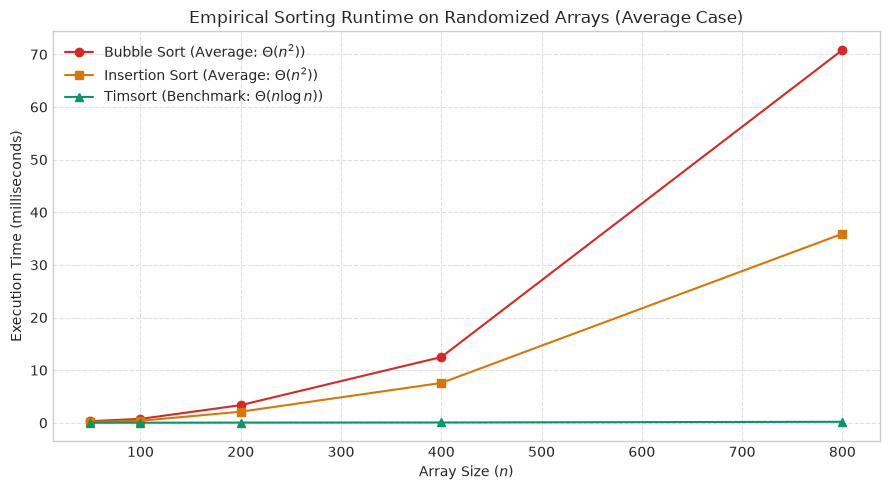

In [9]:
sort_sizes = [50, 100, 200, 400, 800]
bubble_times = []
insertion_times = []
timsort_times = []

# Repeat each trial 5 times for statistical stability
TRIALS = 5

for n in sort_sizes:
    b_acc, i_acc, t_acc = 0.0, 0.0, 0.0
    
    for _ in range(TRIALS):
        sample = [random.randint(1, 10000) for _ in range(n)]
        
        # Benchmark Bubble Sort
        s1 = sample.copy()
        t0 = time.perf_counter()
        bubble_sort_instrumented(s1)
        b_acc += (time.perf_counter() - t0)
        
        # Benchmark Insertion Sort
        s2 = sample.copy()
        t0 = time.perf_counter()
        insertion_sort_instrumented(s2)
        i_acc += (time.perf_counter() - t0)
        
        # Benchmark Built-in Timsort (O(n log n))
        s3 = sample.copy()
        t0 = time.perf_counter()
        s3.sort()
        t_acc += (time.perf_counter() - t0)
        
    bubble_times.append((b_acc / TRIALS) * 1000)      # milliseconds
    insertion_times.append((i_acc / TRIALS) * 1000)    # milliseconds
    timsort_times.append((t_acc / TRIALS) * 1000)      # milliseconds

# Plotting Sorting Runtime Scaling
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sort_sizes, bubble_times, 'o-', color='#DC2626', label='Bubble Sort (Average: $\\Theta(n^2)$)')
ax.plot(sort_sizes, insertion_times, 's-', color='#D97706', label='Insertion Sort (Average: $\\Theta(n^2)$)')
ax.plot(sort_sizes, timsort_times, '^-', color='#059669', label='Timsort (Benchmark: $\\Theta(n \\log n)$)')

ax.set_title("Empirical Sorting Runtime on Randomized Arrays (Average Case)")
ax.set_xlabel("Array Size ($n$)")
ax.set_ylabel("Execution Time (milliseconds)")
ax.legend()
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()


**Analytical Observations on Sorting Runtimes:**  
1. **Quadratic Scaling of Bubble & Insertion Sort:** As $n$ quadruples from $200$ to $800$, execution times for Bubble Sort and Insertion Sort scale by roughly a factor of $4^2 = 16$, validating the theoretical $\Theta(n^2)$ average-case bound.
2. **Insertion Sort Constant Factor Superiority:** Insertion Sort consistently outperforms Bubble Sort by a factor of 2–3x because shifting an element down in-place avoids the 3-step tuple swap overhead of Bubble Sort.
3. **Contrast with $\Theta(n \log n)$:** Timsort remains near the horizontal axis at millisecond fractions, showing the asymptotic dominance of linearithmic algorithms over quadratic ones.


## 7. Master Computational Complexity Matrix (Rosen Section 3.3)

The table below summarizes the exact theoretical complexities derived throughout this assignment:

| Algorithm | Paradigm | Best-Case Time | Average-Case Time | Worst-Case Time | Auxiliary Space | In-Place? | Key Operation |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Finding Maximum** | Linear Scan | $\Theta(n)$ | $\Theta(n)$ | $\Theta(n)$ | $\Theta(1)$ | Yes | Key comparison ($n-1$) |
| **Linear Search** | Brute Force | $\Theta(1)$ | $\Theta(n)$ | $\Theta(n)$ | $\Theta(1)$ | Yes | Equality comparison |
| **Binary Search** | Divide & Conquer | $\Theta(1)$ | $\Theta(\log n)$ | $\Theta(\log n)$ | $\Theta(1)$ | Yes | Interval comparison |
| **Bubble Sort (Opt.)** | Brute / Exchange | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $\Theta(1)$ | Yes | Pairwise swap ($n-1$ best) |
| **Insertion Sort** | Incremental | $\Theta(n)$ | $\Theta(n^2)$ | $\Theta(n^2)$ | $\Theta(1)$ | Yes | Key comparison & shift |
| **Greedy Change** | Greedy | $\Theta(r)$ | $\Theta(r)$ | $\Theta(r)$ | $\Theta(r)$ | Yes | Denomination step |

---

## 8. Academic References and Bibliography
1. **Rosen, Kenneth H.** (2019). *Discrete Mathematics and Its Applications*, 8th Edition. McGraw-Hill Education.  
   *Chapter 3: "Algorithms, the Growth of Functions, and Complexity of Algorithms" (Sections 3.1, 3.2, 3.3).*
2. **Cormen, T. H., Leiserson, C. E., Rivest, R. L., & Stein, C.** (2022). *Introduction to Algorithms*, 4th Edition. MIT Press.
3. **Knuth, Donald E.** (1997). *The Art of Computer Programming*, Volume 1: Fundamental Algorithms, 3rd Edition. Addison-Wesley.
4. **Knuth, Donald E.** (1998). *The Art of Computer Programming*, Volume 3: Sorting and Searching, 2nd Edition. Addison-Wesley.
